# 이탈 위험 점수 검증 노트북 (Day 3)

`app/churn.py` 의 결과를 실제 DB(읽기 전용 계정)로 확인한다. LLM 은 호출하지 않는다.

> **읽기 전에**
> - 모든 성능과 관찰은 **가상 데이터에서 가정한 생성 규칙의 탐지 결과이며 인과가 아니다.**
> - 점수가 높은 팬은 "이탈할 팬"이 아니라 **"이탈 위험 순위가 높은 팬"**이다.
> - 예측 문제: 기준일에 active 인 팬이, 이후 14일 동안 핵심 활동을 한 번도 하지 않는가 (라벨 = 1).

실행: `ai_analyst/notebooks/` 에서 연다. DB 는 SELECT 만 한다.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # ai_analyst/ 를 import 경로에 추가

import matplotlib.pyplot as plt
import pandas as pd

from app import churn
from app.db import run_query
from app.sql_guard import validate_sql

plt.rcParams["font.family"] = "Malgun Gothic"  # 한글 깨짐 방지 (Windows)
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_colwidth", 80)


def sql_df(sql):
    """가드레일(SELECT 전용, 허용 테이블)을 거쳐 읽기 전용 계정으로 실행한다."""
    columns, rows = run_query(validate_sql(sql))
    return pd.DataFrame(rows, columns=columns)


data = churn.load_data()
{name: len(df) for name, df in data.items()}

{'daily': 133206,
 'users': 1750,
 'follows': 2959,
 'subs': 593,
 'artist_daily': 270}

## 1. 인원 검산 (03-31 기준)

확인할 것 두 가지.
1. 마지막 날짜에 active 이면서 탈퇴자를 제외한 인원이 **1,643명**인가 (eval_notes.md 의 검증된 값).
2. **모집단 + 가입 14일 미만 제외 인원 = 1,643명**인가.

SQL 로 직접 세고, 파이썬 코드(`population_check`)의 결과와도 맞는지 본다.

In [2]:
SQL_POPULATION_CHECK = """
SELECT COUNT(DISTINCT m.user_id) AS active_not_deleted,
       COUNT(DISTINCT CASE WHEN u.signup_date_kst <= (SELECT MAX(activity_date_kst) FROM mart_user_daily) - 13
                           THEN m.user_id END) AS population,
       COUNT(DISTINCT CASE WHEN u.signup_date_kst > (SELECT MAX(activity_date_kst) FROM mart_user_daily) - 13
                           THEN m.user_id END) AS excluded_short_tenure
FROM mart_user_daily m
JOIN dim_user u ON u.user_id = m.user_id
WHERE m.activity_date_kst = (SELECT MAX(activity_date_kst) FROM mart_user_daily)
  AND m.activity_status = 'active'
  AND u.is_deleted IS NOT TRUE
"""
from_sql = sql_df(SQL_POPULATION_CHECK).iloc[0]
from_code = churn.population_check(data)
print("SQL  :", dict(from_sql))
print("코드 :", from_code)

assert from_sql["active_not_deleted"] == 1643
assert from_sql["population"] + from_sql["excluded_short_tenure"] == 1643
for key in ("active_not_deleted", "population", "excluded_short_tenure"):
    assert from_sql[key] == from_code[key]
print("검산 통과: 모집단 + 가입 14일 미만 제외 = active 이면서 탈퇴자 제외 = 1,643명")

SQL  : {'active_not_deleted': np.int64(1643), 'population': np.int64(1569), 'excluded_short_tenure': np.int64(74)}
코드 : {'ref_date': Timestamp('2026-03-31 00:00:00'), 'active_not_deleted': 1643, 'population': 1569, 'excluded_short_tenure': 74}
검산 통과: 모집단 + 가입 14일 미만 제외 = active 이면서 탈퇴자 제외 = 1,643명


## 2. 기준일과 분할

- 기준일: 01-15 부터 7일 간격 9개. 학습 5개 / 02-19 는 간격으로 버림 / 평가 3개.
- 학습 마지막 기준일(02-12)의 라벨은 02-26 까지를 본다. 그래서 평가는 02-26 부터 시작한다.
- 아래 실행은 부트스트랩 1,000회를 포함해 1분쯤 걸린다.

In [3]:
r = churn.run_evaluation(data)

parts = []
for name, df in (("학습", r["train"]), ("평가", r["test"])):
    g = df.groupby("ref_date")["label"].agg(n="size", positives="sum", label_rate="mean").reset_index()
    g.insert(0, "part", name)
    parts.append(g)
split_table = pd.concat(parts, ignore_index=True)
split_table["ref_date"] = split_table["ref_date"].dt.strftime("%m-%d")
print("버린 기준일:", [d.strftime("%m-%d") for d in r["dates"]["dropped"]])
print("평가 구간 사용자 중 학습 구간에도 나오는 사용자:",
      len(set(r["test"]["user_id"]) & set(r["train"]["user_id"])), "/", r["test"]["user_id"].nunique())
split_table

버린 기준일: ['02-19']
평가 구간 사용자 중 학습 구간에도 나오는 사용자: 1350 / 1521


,part,ref_date,n,positives,label_rate
0,학습,01-15,1077,72,0.067
1,학습,01-22,1138,73,0.064
2,학습,01-29,1179,58,0.049
3,학습,02-05,1228,60,0.049
4,학습,02-12,1289,60,0.047
5,평가,02-26,1376,41,0.030
6,평가,03-05,1430,58,0.041
7,평가,03-12,1480,69,0.047


## 3. 기준선 대비 성능 (평가 구간)

| 이름 | 내용 |
|---|---|
| M0 | 규칙 기준선: 마지막 핵심 활동 후 일수가 긴 순서 |
| **M1** | **주 모델**: 로지스틱 회귀, 활동 기반 특징만 |
| M2 | M1 + 관계 특징 (팔로우 수, 팔로우 없음, 구독 여부) |
| M3 | M1 + 소통 공백 특징 (체감 공백, 팔로우 없음) |

- **주 지표는 기준일별 AUC 의 평균**이다. 합친 AUC 는 "어느 날짜가 위험한가"만 맞혀도 올라가므로 참고용이다.
- lift = 상위 100명의 실제 비율 / 그 기준일의 전체 비율.
- 신뢰구간은 사용자 단위 부트스트랩 1,000회의 95% 구간이다.

In [4]:
ci = r["ci"]
summary = pd.DataFrame({
    name: {"평균 AUC": m["auc_mean"],
           "AUC 구간 하한": ci.loc[f"{name} auc_mean", "ci_low"], "AUC 구간 상한": ci.loc[f"{name} auc_mean", "ci_high"],
           "합친 AUC(참고)": m["auc_pooled"], "PR-AUC 평균": m["pr_auc_mean"],
           "lift@100 평균": m["lift_mean"],
           "lift 구간 하한": ci.loc[f"{name} lift_mean", "ci_low"], "lift 구간 상한": ci.loc[f"{name} lift_mean", "ci_high"]}
    for name, m in r["metrics"].items()}).T
summary

,평균 AUC,AUC 구간 하한,AUC 구간 상한,합친 AUC(참고),PR-AUC 평균,lift@100 평균,lift 구간 하한,lift 구간 상한
M0,0.591,0.546,0.635,0.598,0.062,1.912,1.286,2.569
M1,0.650,0.609,0.693,0.652,0.071,2.021,1.349,2.740
M2,0.638,0.593,0.679,0.631,0.067,1.513,0.775,2.268
M3,0.640,0.598,0.681,0.638,0.069,1.287,0.647,2.080


In [5]:
by_date = pd.concat([m["by_date"].assign(model=name) for name, m in r["metrics"].items()])
by_date["ref_date"] = by_date["ref_date"].dt.strftime("%m-%d")
print("기준일별 인원 / 양성 비율 / 상위 100명이 차지하는 비율")
display(by_date[by_date["model"] == "M0"][["ref_date", "n", "base_rate", "top_share"]].set_index("ref_date"))
print("기준일별 AUC")
display(by_date.pivot(index="model", columns="ref_date", values="auc"))
print("기준일별 precision@100")
display(by_date.pivot(index="model", columns="ref_date", values="precision_at_n"))
print("기준일별 lift@100")
display(by_date.pivot(index="model", columns="ref_date", values="lift"))

기준일별 인원 / 양성 비율 / 상위 100명이 차지하는 비율


,n,base_rate,top_share
ref_date,,,
02-26,1376,0.030,0.073
03-05,1430,0.041,0.070
03-12,1480,0.047,0.068


기준일별 AUC


ref_date,02-26,03-05,03-12
model,,,
M0,0.551,0.576,0.648
M1,0.644,0.616,0.691
M2,0.667,0.615,0.633
M3,0.648,0.602,0.670


기준일별 precision@100


ref_date,02-26,03-05,03-12
model,,,
M0,0.054,0.050,0.125
M1,0.050,0.056,0.140
M2,0.040,0.060,0.080
M3,0.040,0.050,0.060


기준일별 lift@100


ref_date,02-26,03-05,03-12
model,,,
M0,1.827,1.233,2.677
M1,1.678,1.381,3.003
M2,1.342,1.479,1.716
M3,1.342,1.233,1.287


In [6]:
print("모델 간 차이의 95% 구간 (같은 재표본에서 앞 - 뒤). 구간이 0 을 포함하면 차이가 있다고 말할 수 없다.")
ci[ci.index.str.contains("-")]

모델 간 차이의 95% 구간 (같은 재표본에서 앞 - 뒤). 구간이 0 을 포함하면 차이가 있다고 말할 수 없다.


,ci_low,ci_high
M1-M0 auc_mean,0.019,0.101
M1-M0 lift_mean,-0.465,0.655
M2-M1 auc_mean,-0.040,0.016
M2-M1 lift_mean,-1.341,0.316
M3-M1 auc_mean,-0.029,0.008
M3-M1 lift_mean,-1.502,0.124


**읽는 법**
- M1 은 기준선보다 평균 AUC 가 높고, 그 차이의 구간이 0 을 포함하지 않는다.
  그러나 **상위 100명 정밀도(lift)의 차이는 구간이 0 을 포함**한다. "상위 100명을 더 잘 고른다"는 근거는 없다.
- M2(관계 특징 추가)는 M1 보다 나아지지 않았다.
- M3(소통 공백 추가)는 **이 구간에서는 검증 불가**다. 평가 구간에서 체감 소통 공백 값이 0 과 1 뿐이기 때문이다. "효과 없음"이 아니다.
- AUC 0.65 수준은 약한 신호다. 가정한 생성 규칙의 탐지 결과이며 인과가 아니다.

In [7]:
print("체감 소통 공백 값의 분포 (행 수)")
pd.DataFrame({"학습": r["train"]["min_comm_gap"].value_counts(), "평가": r["test"]["min_comm_gap"].value_counts()}).fillna(0).astype(int).sort_index()

체감 소통 공백 값의 분포 (행 수)


,학습,평가
min_comm_gap,,
0.000,5006,4049
1.000,285,237
2.000,215,0
3.000,225,0
8.000,180,0


## 4. 로지스틱 계수 (M1, 표준화 후)

> **주의: 개별 계수는 해석할 수 없다.**
> `activity_change`(직전 주 대비 변화)는 다른 두 특징으로 정확히 계산되는 값이다:
> `activity_change = 2 x active_days_7 - active_days_14`.
> 세 특징이 같은 정보를 나눠 갖기 때문에 각 계수의 크기와 부호는 불안정하다.
> 예측 점수에는 문제가 없지만, "어느 특징이 얼마나 중요한가"를 이 표로 말하면 안 된다.

- 표준화했으므로 계수는 "그 특징이 표준편차 1만큼 클 때"의 변화다.
- 상관관계일 뿐 원인이 아니다. 마지막 활동 후 일수와 최근 활동일수도 비슷한 정보라 계수를 나눠 갖는다.

In [8]:
display(r["coefficients"]["M1"].to_frame())
print("절편:", round(float(r["models"]["M1"][-1].intercept_[0]), 3))
print("\n학습 구간 특징 간 상관계수")
r["train"][churn.ACTIVITY_FEATURES].corr()

,coef_standardized
days_since_last_core_activity,0.045
active_days_7,-0.276
active_days_14,-0.513
activity_change,0.169
purchased_14d,0.138


절편: -3.059

학습 구간 특징 간 상관계수


,days_since_last_core_activity,active_days_7,active_days_14,activity_change,purchased_14d
days_since_last_core_activity,1.000,-0.681,-0.489,-0.481,-0.063
active_days_7,-0.681,1.000,0.760,0.659,0.090
active_days_14,-0.489,0.760,1.000,0.011,0.142
activity_change,-0.481,0.659,0.011,1.000,-0.026
purchased_14d,-0.063,0.090,0.142,-0.026,1.000


## 5. 군별 실제 라벨 비율 (평가 구간, 분할 모델 M1)

점수 순위로 **상위 10%군 / 11~30%군 / 나머지**로 나눈다.
- 10% 와 20% 라는 경계는 **데이터 근거가 없는 운영 가정**이다.
- "고위험"이라는 이름을 쓰지 않는다. 아래 표처럼 상위 10%군의 실제 비율도 절대값으로는 낮기 때문이다.
- 인원은 (사용자 x 기준일) 행 수다. 기준일마다 따로 군을 나눈 뒤 합쳤다.

이 표는 세그먼트 결과와 항상 함께 나온다 (`churn_report`).

In [9]:
report = churn.churn_report(data)
report["tier_evidence"]

,tier,n,positives,label_rate,rate_ci_low,rate_ci_high,lift,lift_ci_low,lift_ci_high
0,상위 10%군,429,32,0.075,0.049,0.100,1.903,1.326,2.476
1,11~30%군,857,45,0.053,0.039,0.069,1.340,1.053,1.691
2,나머지,3000,91,0.030,0.024,0.037,0.774,0.657,0.882


### [탐색적 추가] 기준선 M0 으로 나눈 군과 나란히 보기

마지막 활동 후 일수가 긴 순서(M0)로 같은 10% / 20% / 나머지를 나눈 표를 옆에 둔다.
**이것은 탐색적 추가이며 모델 평가 설계(M0~M3, 분할, 지표)를 바꾸는 것이 아니다.**
같은 군끼리 실제 비율의 95% 구간이 겹치면 "구분 안 됨"으로 적는다.
M0 은 점수가 정수(일수)라 동점이 많아서 군 경계가 입력 순서에 더 크게 좌우된다.

In [10]:
comparison = churn.tier_comparison(data)
display(comparison)
print("M1 군과 M0 군의 비교:", dict(zip(churn.TIERS, comparison["m1_vs_m0"].iloc[:3])))

,ranking,tier,n,positives,label_rate,rate_ci_low,rate_ci_high,lift,lift_ci_low,lift_ci_high,m1_vs_m0
0,M1 주 모델,상위 10%군,429,32,0.075,0.049,0.100,1.903,1.326,2.476,구분 안 됨 (구간 겹침)
1,M1 주 모델,11~30%군,857,45,0.053,0.039,0.069,1.340,1.053,1.691,구분 안 됨 (구간 겹침)
2,M1 주 모델,나머지,3000,91,0.030,0.024,0.037,0.774,0.657,0.882,구분 안 됨 (구간 겹침)
3,M0 기준선 (탐색적 추가),상위 10%군,429,33,0.077,0.055,0.102,1.962,1.502,2.471,
4,M0 기준선 (탐색적 추가),11~30%군,857,41,0.048,0.035,0.062,1.221,0.946,1.518,
5,M0 기준선 (탐색적 추가),나머지,3000,94,0.031,0.025,0.038,0.799,0.702,0.890,


M1 군과 M0 군의 비교: {'상위 10%군': '구분 안 됨 (구간 겹침)', '11~30%군': '구분 안 됨 (구간 겹침)', '나머지': '구분 안 됨 (구간 겹침)'}


**읽는 법**: 세 군 모두 M1 과 M0 의 구간이 겹친다. 군을 나누는 용도로는 **M1 이 기준선보다 낫다고 말할 수 없다.**
3절에서 M1 의 평균 AUC 가 기준선보다 높았던 것과 함께 읽어야 한다. 전체 순위는 조금 낫지만, 상위 군을 고르는 데서는 차이가 확인되지 않았다.

## 6. 현재 점수 (03-31 기준)

- 모델: 라벨을 알 수 있는 모든 기준일 9개(01-15 ~ 03-12, 02-19 포함)로 M1 을 다시 학습했다.
- **이 모델은 따로 평가할 수 없다.** 03-31 의 정답(이후 14일)이 데이터에 없다.
  위 3절과 5절의 성능은 학습/평가를 나눈 분할 모델의 값이다.

대상 인원: 1569 / 점수 범위: 0.0022 ~ 0.1311


,size,min,median,max
tier,,,,
상위 10%군,157,0.087,0.096,0.131
11~30%군,314,0.061,0.069,0.087
나머지,1098,0.002,0.031,0.061


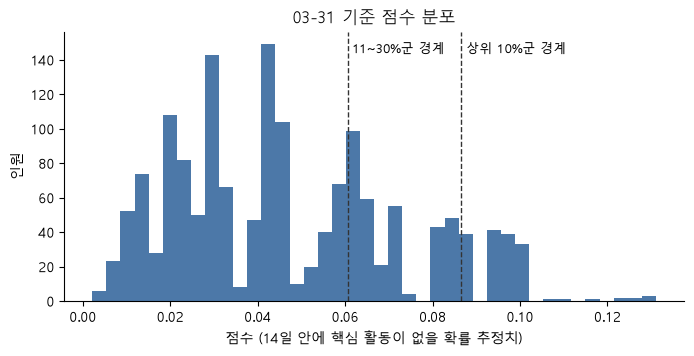

In [11]:
scored = churn.score_current(data)
print("대상 인원:", len(scored), "/ 점수 범위:", round(scored["score"].min(), 4), "~", round(scored["score"].max(), 4))
display(scored.groupby("tier")["score"].agg(["size", "min", "median", "max"]).reindex(churn.TIERS))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(scored["score"], bins=40, color="#4C78A8")
for tier in churn.TIERS[:2]:  # 군 경계선
    cut = scored.loc[scored["tier"] == tier, "score"].min()
    ax.axvline(cut, color="#333333", linestyle="--", linewidth=1)
    ax.text(cut, ax.get_ylim()[1] * 0.92, f" {tier} 경계", fontsize=9)
ax.set_xlabel("점수 (14일 안에 핵심 활동이 없을 확률 추정치)")
ax.set_ylabel("인원")
ax.set_title("03-31 기준 점수 분포")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### 소통 공백 축을 쓸 수 있는가

"공백 김" = 팔로우 중인 아티스트들의 소통 공백 중 최솟값이 4일 이상 (README 발견 1 의 기준).
해당 인원이 없거나 20명 미만이면 이 축은 "해당 없음"으로 보고하고 세그먼트에서 뺀다.

In [12]:
print("03-31 아티스트별 소통 공백")
artist = data["artist_daily"]
display(artist[artist["activity_date_kst"] == artist["activity_date_kst"].max()][["artist_id", "days_since_last_communication"]])
print("03-31 모집단의 체감 소통 공백 분포")
dist = scored.assign(follow=scored["no_follow"].map({0: "팔로우 있음", 1: "팔로우 없음"})).groupby(["follow", "min_comm_gap"]).size().rename("n").reset_index()
display(dist)
print("공백 4일 이상 인원:", report["n_gap_long"], "-> 소통 공백 축:", report["gap_axis"])

03-31 아티스트별 소통 공백


,artist_id,days_since_last_communication
89,artist_001,6.000
179,artist_002,0.000
269,artist_003,14.000


03-31 모집단의 체감 소통 공백 분포


,follow,min_comm_gap,n
0,팔로우 없음,0.000,63
1,팔로우 있음,0.000,841
2,팔로우 있음,6.000,500
3,팔로우 있음,14.000,165


공백 4일 이상 인원: 665 -> 소통 공백 축: 사용


### 이 축은 무엇을 나누고 있는가: 공백 값별 팔로우 아티스트 조합

가설: 아티스트가 3팀뿐이라 체감 소통 공백은 사실상 "어떤 아티스트를 팔로우하는가"와 같다.
- 0일 = artist_002 를 팔로우한다
- 6일 = artist_001 을 팔로우하고 artist_002 는 팔로우하지 않는다
- 14일 = artist_003 만 팔로우한다

In [13]:
combo = churn.gap_by_artist_combo(data, scored)
display(combo)

# 가설을 코드로 확인한다. 하나라도 어긋나면 여기서 멈춘다.
has = lambda name: combo["artists"].str.contains(name)
followers = combo[combo["gap_group"] != "팔로우 없음"]
assert (followers["min_comm_gap"] == 0).eq(has("artist_002")[followers.index]).all()
assert (followers["min_comm_gap"] == 6).eq((has("artist_001") & ~has("artist_002"))[followers.index]).all()
assert (followers["min_comm_gap"] == 14).eq(followers["artists"] == "artist_003").all()
print("가설과 일치: 03-31 의 체감 소통 공백 값은 팔로우하는 아티스트 조합으로 완전히 정해진다.")

,gap_group,min_comm_gap,artists,n
0,공백 4일 미만,0.000,artist_001 + artist_002,269
1,공백 4일 미만,0.000,artist_002,261
2,공백 4일 미만,0.000,artist_001 + artist_002 + artist_003,213
3,공백 4일 미만,0.000,artist_002 + artist_003,98
4,팔로우 없음,0.000,(팔로우 없음),63
5,공백 4일 이상,6.000,artist_001,311
6,공백 4일 이상,6.000,artist_001 + artist_003,189
7,공백 4일 이상,14.000,artist_003,165


가설과 일치: 03-31 의 체감 소통 공백 값은 팔로우하는 아티스트 조합으로 완전히 정해진다.


**결론**: 가설이 데이터와 일치한다. 그래서 세그먼트의 소통 공백 축은
**아티스트 구성 분류이며 이탈 위험 요인으로 검증되지 않았다.**
"공백 4일 이상"은 "artist_002 를 팔로우하지 않는 팬"과 같은 집단이다.

## 7. 세그먼트 (03-31 기준)

군 x 기간 내 구매 경험(2026-01-01 이후) x 소통 공백(공백 4일 이상 / 공백 4일 미만 / 팔로우 없음) = 18칸.
집계만 보여주고 user_id 는 넣지 않는다. 인원이 20명 미만인 칸은 해석을 보류한다.

> 소통 공백 축은 **아티스트 구성 분류이며 이탈 위험 요인으로 검증되지 않았다** (6절).
> 팔로우 없는 팬은 공백 값이 없으므로 "공백 4일 미만"과 섞지 않고 따로 둔다.

In [14]:
segments = report["segments"]
assert segments["n"].sum() == report["total"] == from_code["population"]
assert len(segments) == 18
print("대상 인원:", report["total"], "(세그먼트 합계와 일치)")
display(segments)
for note in report["notes"]:
    print("-", note)

대상 인원: 1569 (세그먼트 합계와 일치)


,tier,purchase,comm_gap,n,share,note
0,상위 10%군,기간 내 구매 경험 있음,공백 4일 이상,28,0.018,
1,상위 10%군,기간 내 구매 경험 있음,공백 4일 미만,23,0.015,
2,상위 10%군,기간 내 구매 경험 있음,팔로우 없음,5,0.003,해석 보류 (20명 미만)
3,상위 10%군,기간 내 구매 경험 없음,공백 4일 이상,63,0.040,
4,상위 10%군,기간 내 구매 경험 없음,공백 4일 미만,33,0.021,
5,상위 10%군,기간 내 구매 경험 없음,팔로우 없음,5,0.003,해석 보류 (20명 미만)
6,11~30%군,기간 내 구매 경험 있음,공백 4일 이상,62,0.040,
7,11~30%군,기간 내 구매 경험 있음,공백 4일 미만,49,0.031,
8,11~30%군,기간 내 구매 경험 있음,팔로우 없음,6,0.004,해석 보류 (20명 미만)
9,11~30%군,기간 내 구매 경험 없음,공백 4일 이상,98,0.062,


- 이 결과는 가상 데이터에서 가정한 생성 규칙의 탐지 결과이며 인과가 아니다. 군은 '이탈할 팬'이 아니라 '이탈 위험 순위가 높은 팬'을 뜻한다.
- 군의 경계(상위 10%, 다음 20%)는 데이터 근거가 없는 운영 가정이다.
- 군별 실제 비율(tier_evidence)은 평가 구간(02-26, 03-05, 03-12)에서 분할 모델로 잰 값이다. 현재 점수용 모델은 정답이 없어 따로 평가할 수 없다.
- 인원이 20명 미만인 칸은 해석을 보류한다.
- 소통 공백 축은 '어떤 아티스트를 팔로우하는가'에 따라 정해지는 아티스트 구성 분류이며, 이탈 위험 요인으로 검증되지 않았다.


## 부록 A. 설계 검토에 쓴 근거 SQL 6건

Day 3 설계를 검토할 때 실행한 SELECT 를 그대로 남긴다. 모두 가드레일을 거쳐 읽기 전용 계정으로 실행한다.
(이 숫자들은 모집단을 정하기 전의 값이라, 매일을 기준일로 쓰고 탈퇴자/신규 가입자를 빼지 않았다.)

In [15]:
FUTURE_ACTIVITY = """
WITH x AS (
  SELECT user_id, activity_date_kst AS t, activity_status AS s, days_since_last_core_activity AS d,
         SUM(CASE WHEN had_core_activity THEN 1 ELSE 0 END) OVER (
           PARTITION BY user_id ORDER BY activity_date_kst ROWS BETWEEN 1 FOLLOWING AND 14 FOLLOWING) AS fut
  FROM mart_user_daily)
"""
EVIDENCE_SQL = {
    "1. 상태 x 기간별 라벨 비율": FUTURE_ACTIVITY + """
SELECT s, CASE WHEN t < '2026-02-01' THEN '1_jan15-31' WHEN t < '2026-03-01' THEN '2_feb' ELSE '3_mar1-17' END AS period,
       COUNT(*) AS n, SUM(CASE WHEN fut = 0 THEN 1 ELSE 0 END) AS churn,
       ROUND(100.0 * SUM(CASE WHEN fut = 0 THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct
FROM x WHERE t BETWEEN '2026-01-15' AND '2026-03-17' GROUP BY 1, 2 ORDER BY 1, 2""",
    "2. 마지막 핵심 활동 후 일수 구간별 라벨 비율": FUTURE_ACTIVITY + """
SELECT CASE WHEN d = 0 THEN 'a_0' WHEN d <= 3 THEN 'b_1-3' WHEN d <= 7 THEN 'c_4-7' WHEN d <= 13 THEN 'd_8-13'
            WHEN d <= 29 THEN 'e_14-29' ELSE 'f_30+' END AS bucket,
       COUNT(*) AS n, ROUND(100.0 * SUM(CASE WHEN fut = 0 THEN 1 ELSE 0 END) / COUNT(*), 1) AS churn_pct
FROM x WHERE t BETWEEN '2026-01-15' AND '2026-03-17' GROUP BY 1 ORDER BY 1""",
    "3. 탈퇴자의 탈퇴 시각 분포": """
SELECT is_deleted, COUNT(*) AS n, COUNT(deleted_at_utc) AS has_deleted_at,
       SUM(CASE WHEN deleted_at_utc < '2026-01-01' THEN 1 ELSE 0 END) AS before_period,
       SUM(CASE WHEN deleted_at_utc >= '2026-01-01' AND deleted_at_utc < '2026-04-01' THEN 1 ELSE 0 END) AS in_period,
       SUM(CASE WHEN deleted_at_utc >= '2026-04-01' THEN 1 ELSE 0 END) AS after_period
FROM dim_user GROUP BY 1""",
    "4. 가입 시기별 사용자 수": """
SELECT CASE WHEN signup_date_kst < '2026-01-01' THEN 'before_2026' ELSE 'in_period' END AS g, COUNT(*) AS n
FROM dim_user GROUP BY 1""",
    "5. 팔로우 이력 범위": """
SELECT COUNT(DISTINCT user_id) AS users_with_follow, COUNT(*) AS follow_rows,
       SUM(CASE WHEN unfollowed_at_utc IS NULL THEN 1 ELSE 0 END) AS still_active,
       MIN(followed_at_utc) AS first_follow_utc
FROM bridge_user_artist_follow""",
    "6. 아티스트별 소통 공백": """
SELECT artist_id, MAX(days_since_last_communication) AS max_gap,
       ROUND(AVG(days_since_last_communication), 1) AS avg_gap,
       SUM(CASE WHEN days_since_last_communication IS NULL THEN 1 ELSE 0 END) AS null_days
FROM mart_artist_daily GROUP BY 1 ORDER BY 1""",
}
for title, sql in EVIDENCE_SQL.items():
    print(title)
    display(sql_df(sql))

1. 상태 x 기간별 라벨 비율


,s,period,n,churn,pct
0,active,1_jan15-31,20992,1180,5.6
1,active,2_feb,39322,1569,4.0
2,active,3_mar1-17,26603,1166,4.4
3,at_risk,1_jan15-31,1767,229,13.0
4,at_risk,2_feb,1898,170,9.0
5,at_risk,3_mar1-17,869,66,7.6
6,dormant,1_jan15-31,14,0,0.0
7,dormant,2_feb,196,2,1.0
8,dormant,3_mar1-17,82,4,4.9


2. 마지막 핵심 활동 후 일수 구간별 라벨 비율


,bucket,n,churn_pct
0,a_0,21685,3.1
1,b_1-3,36662,3.9
2,c_4-7,19287,5.5
3,d_8-13,9283,8.1
4,e_14-29,4534,10.3
5,f_30+,292,2.1


3. 탈퇴자의 탈퇴 시각 분포


,is_deleted,n,has_deleted_at,before_period,in_period,after_period
0,False,1721,0,0,0,0
1,True,29,29,10,3,16


... (2 outputs left out)

5. 팔로우 이력 범위


,users_with_follow,follow_rows,still_active,first_follow_utc
0,1750,2959,2730,2025-12-31 15:14:41+00:00


6. 아티스트별 소통 공백


,artist_id,max_gap,avg_gap,null_days
0,artist_001,6,0.4,0
1,artist_002,8,0.7,1
2,artist_003,14,1.7,0


## 부록 B. 한계 (자세한 내용은 DESIGN.md "10. 알려진 한계")

- 팔로우 이력이 2026-01-01 부터만 있어 팔로우 수/없음 표시가 날짜 대리변수가 될 수 있다.
- 평가 구간에서 체감 소통 공백 값이 0 과 1 뿐이라 소통 공백 특징의 효과를 검증할 수 없다.
- 평가 구간 사용자 대부분이 학습 구간에도 나온다. 새로운 팬에 대한 일반화는 검증하지 못했다.
- `activity_change` 가 다른 두 특징의 선형 결합이라 M1 의 개별 계수는 해석할 수 없다.
- M1 이 기준선보다 나은 것은 평균 AUC 에서만 확인됐다. 상위 100명 정밀도에서는 확인되지 않았다.
- 군의 경계(10%, 20%)는 운영 가정이다. 군 경계의 동점은 입력 순서로 끊는다. 현재 점수용 모델은 정답이 없어 따로 평가할 수 없다.
- 세그먼트의 소통 공백 축은 아티스트 구성 분류이며 이탈 위험 요인으로 검증되지 않았다.
- 가상 데이터의 90일 기간이라 계절성과 장기 효과는 알 수 없다.
- 탈퇴자 29명을 전부 제외했다. 탈퇴 시각이 기준일 이후인 사용자까지 빠지므로 약한 미래 정보 사용이다.